In [1]:
import zipfile
import os
from google.colab import files

# Upload the ZIP file
uploaded = files.upload()

# Get the uploaded ZIP filename
zip_filename = list(uploaded.keys())[0]

# Create a folder for the datasets
os.makedirs("quickcart_data", exist_ok=True)

# Extract all CSV files
with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
    zip_ref.extractall("quickcart_data")

print("Files extracted successfully!")
print(os.listdir("quickcart_data"))


Saving dim_events.zip to dim_events (1).zip
Files extracted successfully!
['dim_suppliers.csv', 'fact_inventory_daily.csv', 'dim_events.csv', 'dim_stores.csv', 'dim_skus.csv']


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:
data_path = "quickcart_data/"

stores = pd.read_csv(data_path + "dim_stores.csv")
skus = pd.read_csv(data_path + "dim_skus.csv")
suppliers = pd.read_csv(
    data_path + "dim_suppliers.csv",
    na_values=['N/A', 'missing', '--', 'NA', 'null']
)
events = pd.read_csv(data_path + "dim_events.csv")
inventory = pd.read_csv(
    data_path + "fact_inventory_daily.csv"
)

print("All datasets loaded successfully!")
print("Stores:", stores.shape)
print("SKUs:", skus.shape)
print("Suppliers:", suppliers.shape)
print("Events:", events.shape)
print("Inventory:", inventory.shape)

All datasets loaded successfully!
Stores: (12, 8)
SKUs: (60, 9)
Suppliers: (15, 6)
Events: (30, 5)
Inventory: (21600, 16)


In [4]:
# Display the first 5 rows
inventory.head()

,date,store_id,sku_id,supplier_id,opening_stock,units_demanded,units_sold,closing_stock,reorder_point,reorder_placed,lead_time_days_expected,lead_time_days_actual,sales_velocity_7d,days_of_cover,is_festival_week,stockout_risk
0,2026-10-01,ST01,SKU001,SUP11,159.9,15,15.0,144.9,36.4,N,1,NaN,15.00,9.66,N,Safe
1,2026-10-02,ST01,SKU001,SUP11,144.9,10,10.0,134.9,36.4,N,1,NaN,12.50,10.79,N,Safe
2,2026-10-03,ST01,SKU001,SUP11,134.9,15,15.0,119.9,36.4,N,1,NaN,13.33,8.99,N,Safe
3,2026-10-04,ST01,SKU001,SUP11,119.9,10,10.0,109.9,36.4,N,1,NaN,12.50,8.79,N,Safe
4,2026-10-05,ST01,SKU001,SUP11,109.9,9,9.0,100.9,36.4,N,1,NaN,11.80,8.55,N,Safe


In [5]:
# Display column names
print("Column Names:")
print(inventory.columns.tolist())

# Dataset information
print("\nDataset Information:")
inventory.info()

Column Names:
['date', 'store_id', 'sku_id', 'supplier_id', 'opening_stock', 'units_demanded', 'units_sold', 'closing_stock', 'reorder_point', 'reorder_placed', 'lead_time_days_expected', 'lead_time_days_actual', 'sales_velocity_7d', 'days_of_cover', 'is_festival_week', 'stockout_risk']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21600 entries, 0 to 21599
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   date                     21600 non-null  object 
 1   store_id                 21600 non-null  object 
 2   sku_id                   21600 non-null  object 
 3   supplier_id              21600 non-null  object 
 4   opening_stock            21600 non-null  float64
 5   units_demanded           21600 non-null  int64  
 6   units_sold               21600 non-null  float64
 7   closing_stock            21600 non-null  float64
 8   reorder_point            21600 non-n

In [6]:
# Count missing values in each column
missing_values = inventory.isnull().sum()

print(missing_values)

date                           0
store_id                       0
sku_id                         0
supplier_id                    0
opening_stock                  0
units_demanded                 0
units_sold                     0
closing_stock                  0
reorder_point                  0
reorder_placed                 0
lead_time_days_expected        0
lead_time_days_actual      19899
sales_velocity_7d              0
days_of_cover                  0
is_festival_week               0
stockout_risk                  0
dtype: int64


In [7]:
print(inventory['stockout_risk'].value_counts())

print("\nPercentage distribution:")
print(
    inventory['stockout_risk']
    .value_counts(normalize=True) * 100
)

stockout_risk
Safe        14131
At-Risk      5186
Imminent     2283
Name: count, dtype: int64

Percentage distribution:
stockout_risk
Safe        65.421296
At-Risk     24.009259
Imminent    10.569444
Name: proportion, dtype: float64


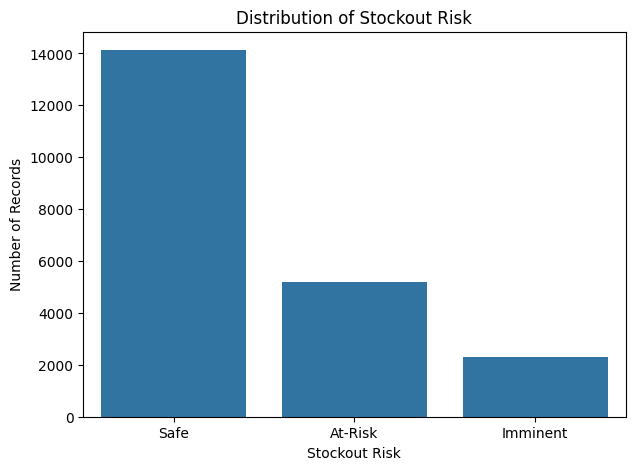

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=inventory,
    x='stockout_risk',
    order=['Safe', 'At-Risk', 'Imminent']
)

plt.title("Distribution of Stockout Risk")
plt.xlabel("Stockout Risk")
plt.ylabel("Number of Records")
plt.show()

stockout_risk       At-Risk   Imminent       Safe
is_festival_week                                 
N                 24.192740   9.511633  66.295628
Y                 21.799517  23.309179  54.891304


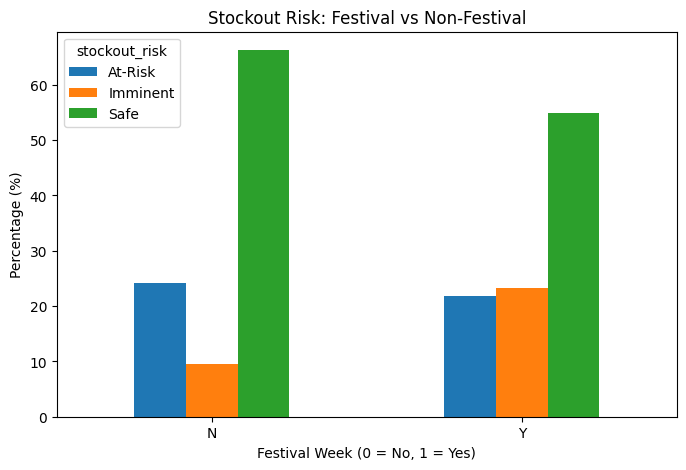

In [9]:
festival_risk = inventory.groupby('is_festival_week')['stockout_risk'].value_counts(normalize=True).unstack() * 100

print(festival_risk)

festival_risk.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("Stockout Risk: Festival vs Non-Festival")
plt.xlabel("Festival Week (0 = No, 1 = Yes)")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.show()

In [10]:
supplier_data = inventory.merge(
    suppliers[['supplier_id', 'reliability_score']],
    on='supplier_id',
    how='left'
)

print(supplier_data[['supplier_id', 'reliability_score', 'stockout_risk']].head())

  supplier_id  reliability_score stockout_risk
0       SUP11               0.83          Safe
1       SUP11               0.83          Safe
2       SUP11               0.83          Safe
3       SUP11               0.83          Safe
4       SUP11               0.83          Safe


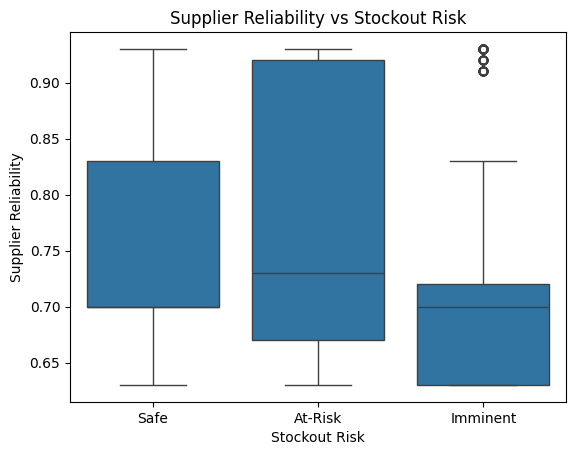

In [11]:

sns.boxplot(
    data=supplier_data,
    x='stockout_risk',
    y='reliability_score'
)

plt.title("Supplier Reliability vs Stockout Risk")
plt.xlabel("Stockout Risk")
plt.ylabel("Supplier Reliability")
plt.show()


stockout_risk    At-Risk   Imminent       Safe
is_perishable                                 
N              24.641813   9.298246  66.059942
Y              22.916667  12.765152  64.318182


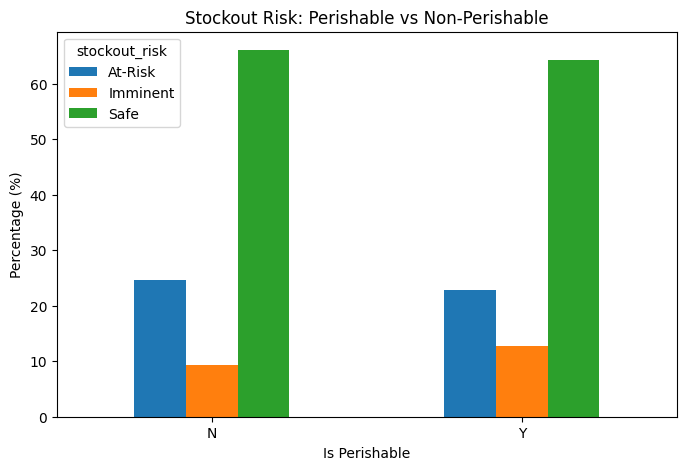

In [12]:
sku_data = inventory.merge(
    skus[['sku_id', 'is_perishable', 'category']],
    on='sku_id',
    how='left'
)

perishable_risk = pd.crosstab(
    sku_data['is_perishable'],
    sku_data['stockout_risk'],
    normalize='index'
) * 100

print(perishable_risk)

perishable_risk.plot(kind='bar', figsize=(8, 5))

plt.title("Stockout Risk: Perishable vs Non-Perishable")
plt.xlabel("Is Perishable")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.show()


In [13]:

# Merge inventory with store details
df = inventory.merge(stores, on='store_id', how='left')

# Merge with SKU details
df = df.merge(skus, on='sku_id', how='left', suffixes=('', '_sku'))

# Merge with supplier details
df = df.merge(suppliers, on='supplier_id', how='left', suffixes=('', '_supplier'))

# Merge with festival/event details
df['date'] = pd.to_datetime(df['date'])
events['date'] = pd.to_datetime(events['date'])

df = df.merge(events, on='date', how='left')

print("Final dataset shape:", df.shape)
print(df.head())


Final dataset shape: (21600, 40)
        date store_id  sku_id supplier_id  opening_stock  units_demanded  \
0 2026-10-01     ST01  SKU001       SUP11          159.9              15   
1 2026-10-02     ST01  SKU001       SUP11          144.9              10   
2 2026-10-03     ST01  SKU001       SUP11          134.9              15   
3 2026-10-04     ST01  SKU001       SUP11          119.9              10   
4 2026-10-05     ST01  SKU001       SUP11          109.9               9   

   units_sold  closing_stock  reorder_point reorder_placed  ...  \
0        15.0          144.9           36.4              N  ...   
1        10.0          134.9           36.4              N  ...   
2        15.0          119.9           36.4              N  ...   
3        10.0          109.9           36.4              N  ...   
4         9.0          100.9           36.4              N  ...   

   supplier_id_sku          supplier_name          categories_supplied  \
0            SUP11  Coastal Foods

In [14]:

# Convert supplier reliability into numeric format
df['reliability_score'] = pd.to_numeric(
    df['reliability_score'], errors='coerce'
)

# Fill missing reliability with category median
df['reliability_score'] = df.groupby('category')['reliability_score'].transform(
    lambda x: x.fillna(x.median())
)

# Fill any remaining missing reliability with overall median
df['reliability_score'] = df['reliability_score'].fillna(
    df['reliability_score'].median()
)

# Create useful features
df['reorder_gap'] = df['reorder_point'] - df['closing_stock']

df['days_of_cover_ratio'] = (
    df['days_of_cover'] / df['lead_time_days_expected'].replace(0, np.nan)
)

df['days_of_cover_ratio'] = df['days_of_cover_ratio'].fillna(0)

df['day_of_month'] = df['date'].dt.day
df['day_of_week'] = df['date'].dt.dayofweek

print("Data cleaning and feature engineering completed!")
print(df.shape)


Data cleaning and feature engineering completed!
(21600, 44)


In [15]:

# Separate target
y = df['stockout_risk']

# Remove target and columns not needed for prediction
X = df.drop(columns=[
    'stockout_risk',
    'date',
    'city_display',
    'event_name',
    'supplier_name',
    'categories_supplied'
], errors='ignore')

# Convert categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True)

# Handle any remaining missing values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median(numeric_only=True))
X = X.fillna(0)

print("Features ready:", X.shape)
print("Target classes:", y.unique())


Features ready: (21600, 198)
Target classes: ['Safe' 'At-Risk' 'Imminent']


In [16]:

# October 1–23 for training, October 24–30 for testing
train_mask = df['date'] < '2026-10-24'

X_train = X.loc[train_mask]
X_test = X.loc[~train_mask]

y_train = y.loc[train_mask]
y_test = y.loc[~train_mask]

print("Training records:", X_train.shape)
print("Testing records:", X_test.shape)


Training records: (16560, 198)
Testing records: (5040, 198)


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Create Logistic Regression model
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    )
)

# Train model
lr_model.fit(X_train, y_train)

# Predict
lr_predictions = lr_model.predict(X_test)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


In [18]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=15,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Train model
rf_model.fit(X_train, y_train)

# Predict
rf_predictions = rf_model.predict(X_test)

print("Random Forest trained successfully!")


Random Forest trained successfully!


In [19]:
from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(y_test, lr_predictions)
rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")
print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")


Logistic Regression Accuracy: 92.5 %
Random Forest Accuracy: 93.87 %


In [20]:
print("RANDOM FOREST CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    rf_predictions,
    labels=['Safe', 'At-Risk', 'Imminent'],
    zero_division=0
))

RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Safe       1.00      1.00      1.00      3139
     At-Risk       0.82      0.94      0.87      1126
    Imminent       0.90      0.70      0.79       775

    accuracy                           0.94      5040
   macro avg       0.90      0.88      0.89      5040
weighted avg       0.94      0.94      0.94      5040



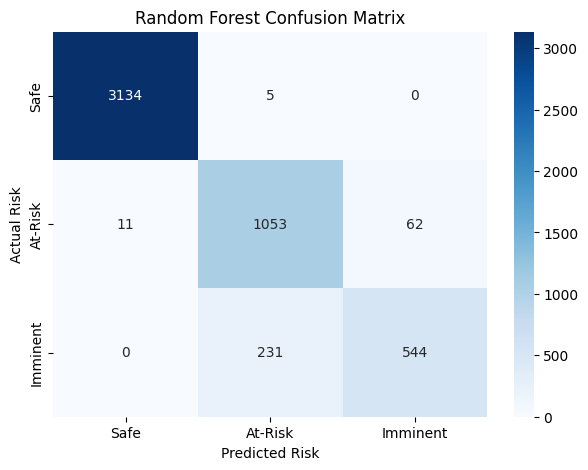

In [21]:
cm = confusion_matrix(
    y_test,
    rf_predictions,
    labels=['Safe', 'At-Risk', 'Imminent']
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Safe', 'At-Risk', 'Imminent'],
    yticklabels=['Safe', 'At-Risk', 'Imminent']
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")
plt.show()


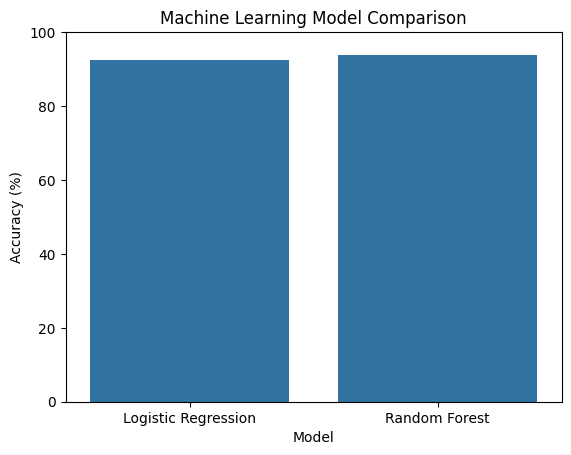

                 Model   Accuracy
0  Logistic Regression  92.500000
1        Random Forest  93.869048


In [22]:
model_results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest'],
    'Accuracy': [lr_accuracy * 100, rf_accuracy * 100]
})

sns.barplot(data=model_results, x='Model', y='Accuracy')

plt.title("Machine Learning Model Comparison")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.show()

print(model_results)


Top 10 Important Features:
                   Feature  Importance
8            days_of_cover    0.192570
20     days_of_cover_ratio    0.181821
19             reorder_gap    0.163762
3            closing_stock    0.070866
0            opening_stock    0.041271
6    lead_time_days_actual    0.032241
7        sales_velocity_7d    0.024116
105       reorder_placed_Y    0.019359
4            reorder_point    0.017651
1           units_demanded    0.016519


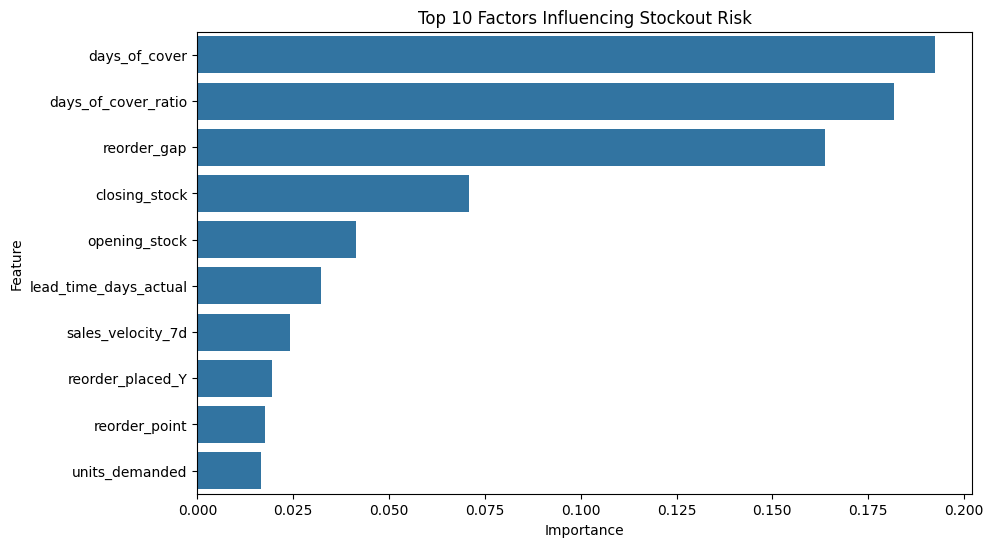

In [23]:
importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("Top 10 Important Features:")
print(importance.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Factors Influencing Stockout Risk")
plt.show()


In [24]:
from sklearn.metrics import recall_score, precision_score, f1_score

for label in ['Safe', 'At-Risk', 'Imminent']:
    mask = y_test == label

    print(f"\n{label}")
    print("Recall:", round(recall_score(
        y_test, rf_predictions, labels=[label],
        average=None, zero_division=0
    )[0], 4))



Safe
Recall: 0.9984

At-Risk
Recall: 0.9352

Imminent
Recall: 0.7019


In [25]:
final_predictions = pd.DataFrame({
    'Date': df.loc[X_test.index, 'date'],
    'Store_ID': df.loc[X_test.index, 'store_id'],
    'SKU_ID': df.loc[X_test.index, 'sku_id'],
    'Actual_Risk': y_test,
    'Predicted_Risk': rf_predictions
})

print(final_predictions.head(15))

         Date Store_ID  SKU_ID Actual_Risk Predicted_Risk
23 2026-10-24     ST01  SKU001     At-Risk        At-Risk
24 2026-10-25     ST01  SKU001        Safe           Safe
25 2026-10-26     ST01  SKU001        Safe           Safe
26 2026-10-27     ST01  SKU001        Safe           Safe
27 2026-10-28     ST01  SKU001        Safe           Safe
28 2026-10-29     ST01  SKU001        Safe           Safe
29 2026-10-30     ST01  SKU001        Safe           Safe
53 2026-10-24     ST02  SKU001        Safe           Safe
54 2026-10-25     ST02  SKU001        Safe           Safe
55 2026-10-26     ST02  SKU001        Safe           Safe
56 2026-10-27     ST02  SKU001     At-Risk        At-Risk
57 2026-10-28     ST02  SKU001        Safe           Safe
58 2026-10-29     ST02  SKU001        Safe           Safe
59 2026-10-30     ST02  SKU001        Safe           Safe
83 2026-10-24     ST03  SKU001        Safe           Safe


In [26]:
import joblib

# Save trained Random Forest model
joblib.dump(rf_model, 'quickcart_stockout_model.pkl')

# Save prediction results
final_predictions.to_csv(
    'quickcart_predictions.csv',
    index=False
)

# Save feature importance
importance.to_csv(
    'quickcart_feature_importance.csv',
    index=False
)

print("All project files saved successfully!")

from google.colab import files

files.download('quickcart_stockout_model.pkl')
files.download('quickcart_predictions.csv')
files.download('quickcart_feature_importance.csv')

All project files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Detailed model evaluation
print("FINAL RANDOM FOREST MODEL EVALUATION\n")

print(classification_report(
    y_test,
    rf_predictions,
    labels=['Safe', 'At-Risk', 'Imminent'],
    zero_division=0
))

# Check Imminent recall separately
report = classification_report(
    y_test,
    rf_predictions,
    labels=['Safe', 'At-Risk', 'Imminent'],
    output_dict=True,
    zero_division=0
)

print("Imminent Stockout Recall:",
      round(report['Imminent']['recall'] * 100, 2), "%")

print("Imminent Stockout Precision:",
      round(report['Imminent']['precision'] * 100, 2), "%")


FINAL RANDOM FOREST MODEL EVALUATION

              precision    recall  f1-score   support

        Safe       1.00      1.00      1.00      3139
     At-Risk       0.82      0.94      0.87      1126
    Imminent       0.90      0.70      0.79       775

    accuracy                           0.94      5040
   macro avg       0.90      0.88      0.89      5040
weighted avg       0.94      0.94      0.94      5040

Imminent Stockout Recall: 70.19 %
Imminent Stockout Precision: 89.77 %


In [28]:
# Identify columns that may contain information
# unavailable at the time of an early stockout forecast

possible_leakage = [
    'lead_time_days_actual',
    'closing_stock',
    'units_sold',
    'units_demanded'
]

print("Columns found:")
print([col for col in possible_leakage if col in X_train.columns])

# Remove these columns for a conservative test
X_train_clean = X_train.drop(
    columns=possible_leakage,
    errors='ignore'
)

X_test_clean = X_test.drop(
    columns=possible_leakage,
    errors='ignore'
)

# Train another Random Forest
rf_clean = RandomForestClassifier(
    n_estimators=150,
    max_depth=15,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_clean.fit(X_train_clean, y_train)

clean_predictions = rf_clean.predict(X_test_clean)

print("\nConservative Model Accuracy:",
      round(accuracy_score(y_test, clean_predictions) * 100, 2), "%")

print("\nConservative Model Classification Report:")
print(classification_report(
    y_test,
    clean_predictions,
    labels=['Safe', 'At-Risk', 'Imminent'],
    zero_division=0
))


Columns found:
['lead_time_days_actual', 'closing_stock', 'units_sold', 'units_demanded']

Conservative Model Accuracy: 93.19 %

Conservative Model Classification Report:
              precision    recall  f1-score   support

        Safe       1.00      1.00      1.00      3139
     At-Risk       0.80      0.92      0.86      1126
    Imminent       0.87      0.68      0.76       775

    accuracy                           0.93      5040
   macro avg       0.89      0.87      0.87      5040
weighted avg       0.93      0.93      0.93      5040



In [29]:

extra_risky_features = [
    'reorder_gap',
    'days_of_cover',
    'days_of_cover_ratio',
    'reorder_placed'
]

X_train_final = X_train_clean.drop(
    columns=extra_risky_features,
    errors='ignore'
)

X_test_final = X_test_clean.drop(
    columns=extra_risky_features,
    errors='ignore'
)

final_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=15,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train_final, y_train)

final_predictions = final_model.predict(X_test_final)

print("Final Model Accuracy:",
      round(accuracy_score(y_test, final_predictions)*100, 2), "%")

print(classification_report(
    y_test,
    final_predictions,
    labels=['Safe', 'At-Risk', 'Imminent'],
    zero_division=0
))


Final Model Accuracy: 71.15 %
              precision    recall  f1-score   support

        Safe       0.80      0.88      0.84      3139
     At-Risk       0.52      0.43      0.47      1126
    Imminent       0.52      0.44      0.48       775

    accuracy                           0.71      5040
   macro avg       0.61      0.58      0.60      5040
weighted avg       0.69      0.71      0.70      5040



In [30]:
# Keep end-of-day inventory information.
# Remove actual lead time because it is not known in advance.

X_train_operational = X_train.drop(
    columns=['lead_time_days_actual'],
    errors='ignore'
)

X_test_operational = X_test.drop(
    columns=['lead_time_days_actual'],
    errors='ignore'
)

operational_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=15,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

operational_model.fit(X_train_operational, y_train)

operational_predictions = operational_model.predict(
    X_test_operational
)

print("Operational Model Accuracy:",
      round(accuracy_score(y_test, operational_predictions)*100, 2), "%")

print(classification_report(
    y_test,
    operational_predictions,
    labels=['Safe', 'At-Risk', 'Imminent'],
    zero_division=0
))


Operational Model Accuracy: 93.25 %
              precision    recall  f1-score   support

        Safe       1.00      1.00      1.00      3139
     At-Risk       0.81      0.92      0.86      1126
    Imminent       0.87      0.68      0.77       775

    accuracy                           0.93      5040
   macro avg       0.89      0.87      0.87      5040
weighted avg       0.93      0.93      0.93      5040



In [31]:

import joblib
import pandas as pd
from google.colab import files

# Save model and its required feature information
model_bundle = {
    'model': operational_model,
    'feature_columns': X_train_operational.columns.tolist(),
    'classes': operational_model.classes_.tolist()
}

joblib.dump(model_bundle, 'QuickCart_Final_Model.pkl')

# Create final predictions
final_predictions = pd.DataFrame({
    'Date': df.loc[X_test.index, 'date'],
    'Store_ID': df.loc[X_test.index, 'store_id'],
    'SKU_ID': df.loc[X_test.index, 'sku_id'],
    'Actual_Risk': y_test,
    'Predicted_Risk': operational_predictions
})

final_predictions.to_csv(
    'QuickCart_Final_Predictions.csv',
    index=False
)

# Save feature importance
final_importance = pd.DataFrame({
    'Feature': X_train_operational.columns,
    'Importance': operational_model.feature_importances_
}).sort_values('Importance', ascending=False)

final_importance.to_csv(
    'QuickCart_Feature_Importance.csv',
    index=False
)

print("Final operational model and project outputs saved!")

# Download all three files
files.download('QuickCart_Final_Model.pkl')
files.download('QuickCart_Final_Predictions.csv')
files.download('QuickCart_Feature_Importance.csv')


Final operational model and project outputs saved!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>